#### yfinance Kullanarak Hisse Senedi Bilgilerini Alma
#### yfinance Kullanarak Geçmiş Hisse Fiyatı Verilerini Alma
#### yfinance Kullanarak Geçmiş Temettü Verilerini Alma

In [13]:
import yfinance as yf
import pandas as pd
import numpy as np

#### Ticker modülünü kullanarak, veri çekme işlevlerine erişmemizi sağlayacak bir nesne oluşturabiliriz. Bunu yapmak için ilgili hisse senedinin borsa sembolünü belirtmemiz gerekir; burada şirket Apple, borsa sembolü ise AAPL'dir.

In [ ]:
apple = yf.Ticker("AAPL")
apple_info = apple.info
apple_info                      ## İÇERİK HAKKINDA BİLGİLERİ ALALIM json dosyası komple
print("")

#### Veriler bir Pandas DataFrame'i formatında döndürülür. Tarih bilgisinin indeks olarak kullanıldığı bu yapıda; her bir gün için hissenin Açılış, En Yüksek, En Düşük, Kapanış ve Hacim değerleri ile hisse bölünmeleri sunulur.

In [31]:
# apple_hist = apple.history(period = "max")      ## mesela baştan sonra bütün veriler
apple_hist = apple.history(start = "2026-01-01", end = "2026-12-31")
apple_hist

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-01-02 00:00:00-05:00,271.520960,277.085800,268.269799,270.274353,37838100,0.0,0.0
2026-01-05 00:00:00-05:00,269.905376,270.773009,265.417591,266.534546,45647200,0.0,0.0
2026-01-06 00:00:00-05:00,266.275247,266.823742,261.408488,261.647827,52352100,0.0,0.0
2026-01-07 00:00:00-05:00,262.485556,262.964234,259.104744,259.623322,48309800,0.0,0.0
2026-01-08 00:00:00-05:00,256.322286,258.586144,255.005878,258.336823,50419300,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-05 00:00:00-04:00,332.820007,336.209991,331.649994,332.890015,34400900,0.0,0.0
2026-10-06 00:00:00-04:00,332.279999,334.380005,330.619995,333.630005,30449000,0.0,0.0
2026-10-07 00:00:00-04:00,336.959991,338.670013,332.779999,336.670013,34147900,0.0,0.0


#### Artık ihtiyaç duyduğumuz veri türünü elde etmek için fonksiyonlara ve değişkenlere erişebiliriz.

In [32]:
country = apple_info["country"]
print(country)

United States


#### İndexleri sıfırlayalım

In [34]:
apple_hist = apple_hist.reset_index()
apple_hist

,index,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,0,2026-01-02 00:00:00-05:00,271.520960,277.085800,268.269799,270.274353,37838100,0.0,0.0
1,1,2026-01-05 00:00:00-05:00,269.905376,270.773009,265.417591,266.534546,45647200,0.0,0.0
2,2,2026-01-06 00:00:00-05:00,266.275247,266.823742,261.408488,261.647827,52352100,0.0,0.0
3,3,2026-01-07 00:00:00-05:00,262.485556,262.964234,259.104744,259.623322,48309800,0.0,0.0
4,4,2026-01-08 00:00:00-05:00,256.322286,258.586144,255.005878,258.336823,50419300,0.0,0.0
...,...,...,...,...,...,...,...,...,...
189,189,2026-10-05 00:00:00-04:00,332.820007,336.209991,331.649994,332.890015,34400900,0.0,0.0
190,190,2026-10-06 00:00:00-04:00,332.279999,334.380005,330.619995,333.630005,30449000,0.0,0.0
191,191,2026-10-07 00:00:00-04:00,336.959991,338.670013,332.779999,336.670013,34147900,0.0,0.0
192,192,2026-10-08 00:00:00-04:00,336.820007,341.570007,335.899994,340.420013,35332400,0.0,0.0


#### Açılış fiyatına göre çizebilirz.

<Axes: xlabel='Date'>

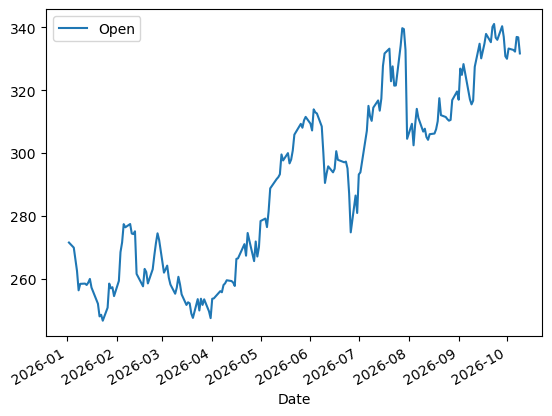

In [35]:
apple_hist.plot(x ="Date", y="Open")

### Temettü Verilerini çekme(dividends)

In [ ]:
apple_temettü = apple_hist.Dividends
apple_temettü.sum()                     ## 2026'da toplam 80 cent vermiş mesela

np.float64(0.8)

In [ ]:
apple_genel_list = apple.history(period ="max")
apple_genel_temettü = apple_genel_list.Dividends      ## bu zamana kadarki bütün temettüleri

np.float64(10.603563999999999)

#### Temettüleri zaman içindeki değişimleriyle grafiğe dökebiliriz:

<Axes: xlabel='Date'>

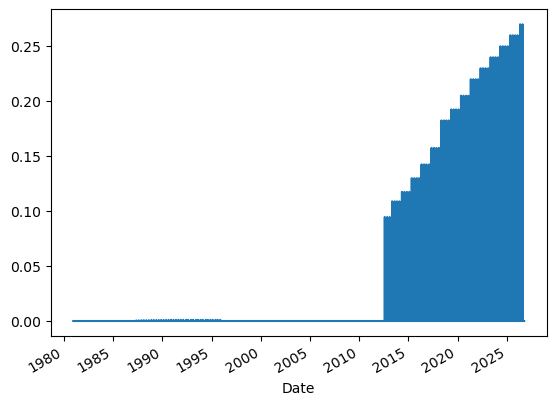

In [47]:
apple_genel_temettü.plot()